<a href="https://colab.research.google.com/github/mahithamodepalli29/Fraud_Detection/blob/main/Fraud_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import files

uploaded = files.upload()

Saving fraud.csv to fraud.csv


In [5]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import warnings
warnings.filterwarnings('ignore')

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [6]:
df = pd.read_csv('fraud.csv')

print("Dataset Loaded Successfully!")

df.head()

Dataset Loaded Successfully!


,transaction_amount,hour_of_day,is_weekend,num_items,customer_age,prev_transactions,distance_from_home,device_type,network_quality,is_first_transaction,store_type,velocity_score,is_fraud
0,161.363691,3.0,0.0,2.0,18.000000,2.0,26.539742,1.0,48.403937,0.0,0.0,3.718296,0
1,116.202851,1.0,1.0,4.0,26.285818,2.0,50.714402,NaN,76.144979,0.0,0.0,4.951272,0
2,1.000000,2.0,0.0,5.0,18.000000,NaN,9.467935,0.0,67.600316,0.0,0.0,4.556043,0
3,48.780618,2.0,0.0,3.0,44.471190,NaN,41.077068,0.0,94.825526,0.0,0.0,6.918437,0
4,NaN,3.0,0.0,4.0,38.733609,8.0,NaN,2.0,100.000000,0.0,1.0,5.535335,1


In [7]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
display(df.describe())

Dataset Shape: (7000, 13)

Column Names:
Index(['transaction_amount', 'hour_of_day', 'is_weekend', 'num_items',
       'customer_age', 'prev_transactions', 'distance_from_home',
       'device_type', 'network_quality', 'is_first_transaction', 'store_type',
       'velocity_score', 'is_fraud'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   transaction_amount    6440 non-null   float64
 1   hour_of_day           6650 non-null   float64
 2   is_weekend            6860 non-null   float64
 3   num_items             6790 non-null   float64
 4   customer_age          6160 non-null   float64
 5   prev_transactions     6510 non-null   float64
 6   distance_from_home    6300 non-null   float64
 7   device_type           6720 non-null   float64
 8   network_quality       6370 non-null   f

,transaction_amount,hour_of_day,is_weekend,num_items,customer_age,prev_transactions,distance_from_home,device_type,network_quality,is_first_transaction,store_type,velocity_score,is_fraud
count,6440.000000,6650.000000,6860.000000,6790.000000,6160.000000,6510.000000,6300.000000,6720.000000,6370.000000,6790.000000,6860.000000,5950.000000,7000.000000
mean,100.014648,2.200902,0.108601,2.977320,36.200811,4.457604,24.830735,0.698810,74.094739,0.095876,0.286735,5.007450,0.103000
std,49.091009,0.677906,0.311160,1.712444,13.283996,4.881635,24.314751,0.776802,18.003855,0.294443,0.452270,2.007633,0.303981
min,1.000000,1.000000,0.000000,0.000000,18.000000,0.000000,0.004282,0.000000,0.477174,0.000000,0.000000,-1.853966,0.000000
25%,65.711569,2.000000,0.000000,2.000000,25.244168,1.000000,7.387315,0.000000,61.586731,0.000000,0.000000,3.697990,0.000000
50%,99.482201,2.000000,0.000000,3.000000,35.361187,3.000000,17.321496,1.000000,75.306346,0.000000,0.000000,4.992099,0.000000
75%,132.897923,3.000000,0.000000,4.000000,45.500089,6.000000,34.857859,1.000000,88.253574,0.000000,1.000000,6.342852,0.000000
max,296.311885,3.000000,1.000000,13.000000,80.000000,40.000000,224.699757,2.000000,100.000000,1.000000,1.000000,12.659564,1.000000


Missing Values:
transaction_amount       560
hour_of_day              350
is_weekend               140
num_items                210
customer_age             840
prev_transactions        490
distance_from_home       700
device_type              280
network_quality          630
is_first_transaction     210
store_type               140
velocity_score          1050
is_fraud                   0
dtype: int64


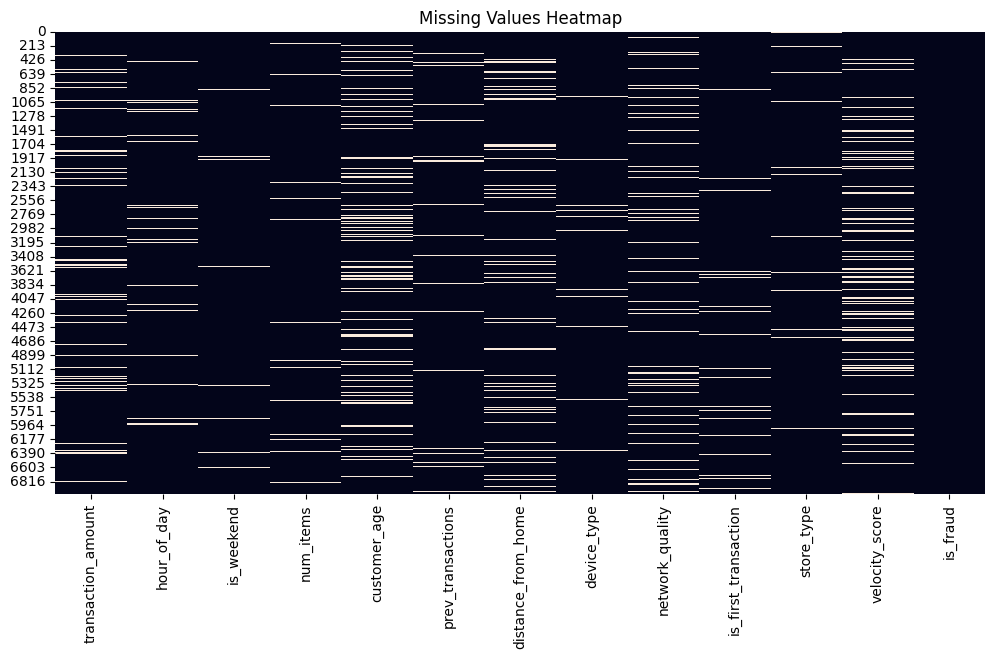

In [8]:
print("Missing Values:")

print(df.isnull().sum())

plt.figure(figsize=(12,6))

sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values Heatmap")

plt.show()

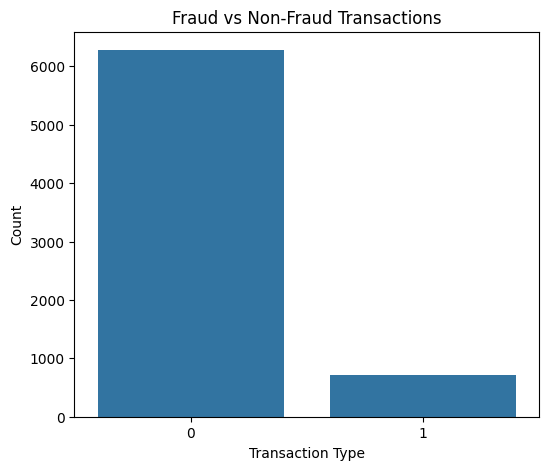

In [9]:
plt.figure(figsize=(6,5))

sns.countplot(x='is_fraud', data=df)

plt.title("Fraud vs Non-Fraud Transactions")

plt.xlabel("Transaction Type")

plt.ylabel("Count")

plt.show()

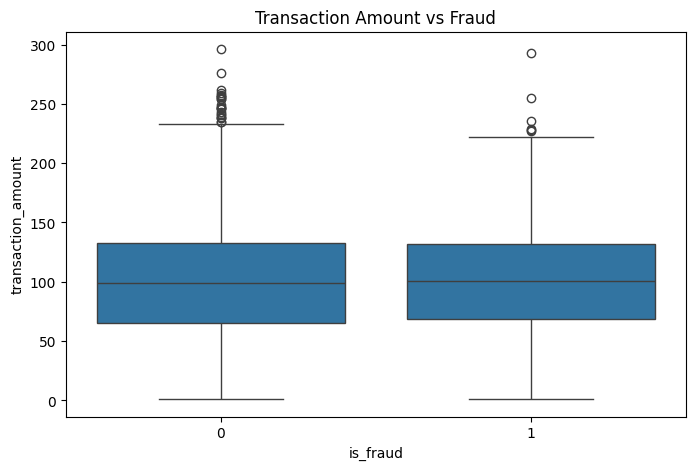

In [10]:
plt.figure(figsize=(8,5))

sns.boxplot(x='is_fraud',
            y='transaction_amount',
            data=df)

plt.title("Transaction Amount vs Fraud")

plt.show()

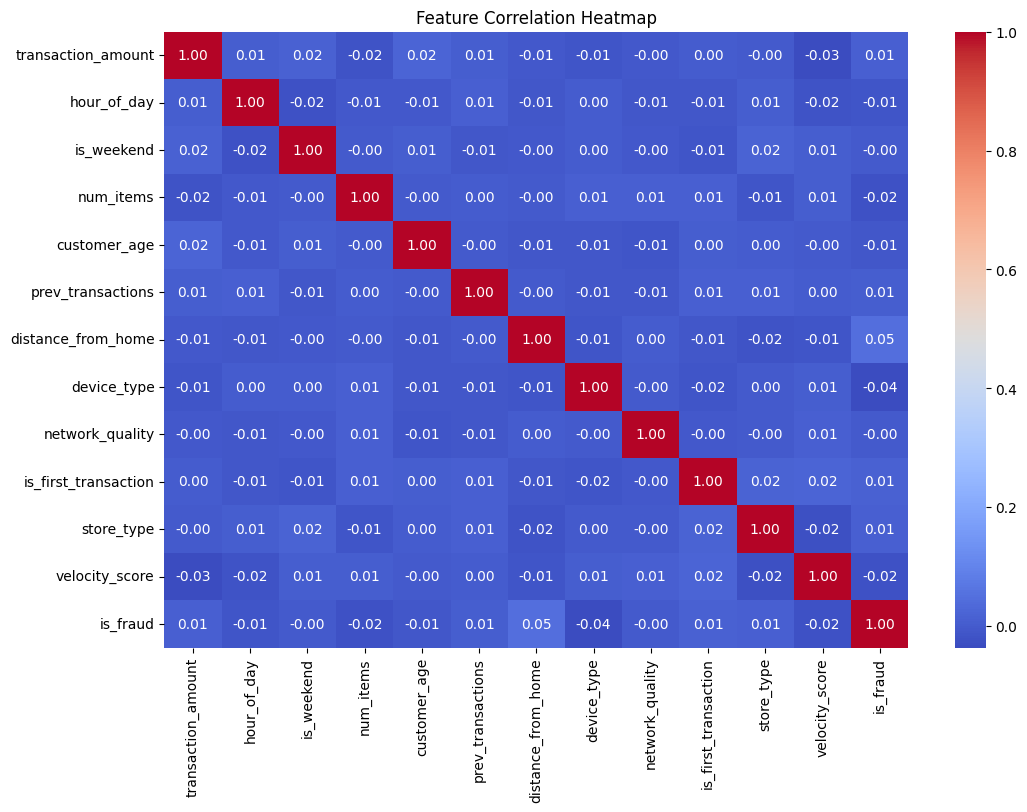

In [11]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [12]:
X = df.drop('is_fraud', axis=1)

y = df['is_fraud']

print("Input Features:", X.shape)

print("Target Variable:", y.shape)

Input Features: (7000, 12)
Target Variable: (7000,)


In [15]:
categorical_cols = ['device_type', 'store_type']

numerical_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numerical_cols),
    ('cat', categorical_pipeline, categorical_cols)
])

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (5600, 12)
Testing Data: (1400, 12)


In [17]:
lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000
    ))
])

lr_model.fit(X_train, y_train)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


In [18]:
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest Training Completed!")

Random Forest Training Completed!


In [19]:
y_pred_lr = lr_model.predict(X_test)

y_pred_rf = rf_model.predict(X_test)

print("Logistic Regression Predictions:")
print(y_pred_lr[:10])

print("\nRandom Forest Predictions:")
print(y_pred_rf[:10])

Logistic Regression Predictions:
[1 0 0 1 1 1 0 1 1 0]

Random Forest Predictions:
[0 0 0 0 0 0 0 0 0 0]


In [20]:
models = {
    'Logistic Regression': lr_model,
    'Random Forest': rf_model
}

for name, model in models.items():

    predictions = model.predict(X_test)

    print("\n", name)

    print("Accuracy:",
          accuracy_score(y_test, predictions))

    print("Precision:",
          precision_score(y_test, predictions))

    print("Recall:",
          recall_score(y_test, predictions))

    print("F1 Score:",
          f1_score(y_test, predictions))

    print("\nClassification Report:")

    print(classification_report(y_test, predictions))


 Logistic Regression
Accuracy: 0.5628571428571428
Precision: 0.11513157894736842
Recall: 0.4861111111111111
F1 Score: 0.18617021276595744

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.57      0.70      1256
           1       0.12      0.49      0.19       144

    accuracy                           0.56      1400
   macro avg       0.51      0.53      0.44      1400
weighted avg       0.83      0.56      0.65      1400


 Random Forest
Accuracy: 0.8971428571428571
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Classification Report:
              precision    recall  f1-score   support

           0       0.90      1.00      0.95      1256
           1       0.00      0.00      0.00       144

    accuracy                           0.90      1400
   macro avg       0.45      0.50      0.47      1400
weighted avg       0.80      0.90      0.85      1400



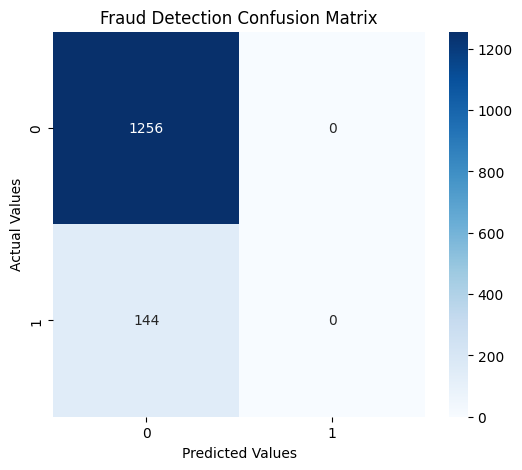

In [21]:
y_pred = rf_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Fraud Detection Confusion Matrix")

plt.xlabel("Predicted Values")

plt.ylabel("Actual Values")

plt.show()

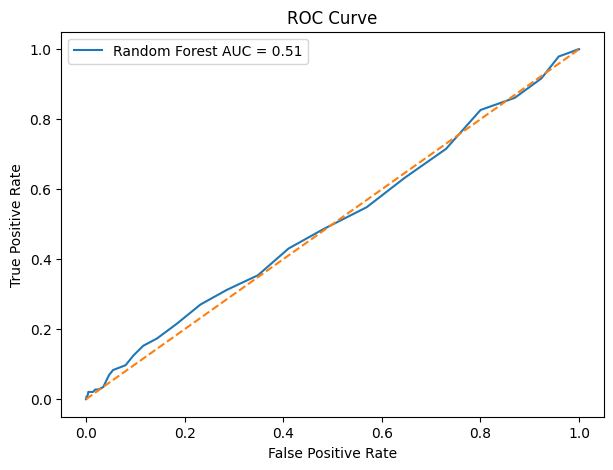

In [22]:
from sklearn.metrics import roc_curve, auc

y_probability = rf_model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    label=f'Random Forest AUC = {roc_auc:.2f}'
)

plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

In [24]:
new_transaction = pd.DataFrame([{
    'transaction_amount': 250,
    'hour_of_day': 3,
    'is_weekend': 1,
    'num_items': 5,
    'customer_age': 25,
    'prev_transactions': 1,
    'distance_from_home': 100,
    'device_type': 2,
    'network_quality': 30,
    'is_first_transaction': 1,
    'store_type': 1,
    'velocity_score': 10
}])

prediction = rf_model.predict(new_transaction)

if prediction[0] == 1:
    print("⚠️ Fraudulent Transaction Detected!")
else:
    print("✅ Genuine Transaction")

✅ Genuine Transaction
